# From Static Ledgers to Living Processes — Getting Started

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/petescarth/multitask-eco-condition/blob/main/examples/getting_started.ipynb)

This end-to-end notebook accompanies the talk **[From Static Ledgers to Living Processes](https://petescarth.com/multitask-eco-condition)** ([GitHub repository](https://github.com/petescarth/multitask-eco-condition)). It lets you reproduce the core public pipeline across **five runnable parts**:

1. **Public Earth Observation & Ecological Data:** Dequantise 64-D **AlphaEarth Foundations** embeddings (`GOOGLE/SATELLITE_EMBEDDING/V1/ANNUAL`), compute local **IBRA v7** subregion reference cosine similarities, and inspect why **HCAS** and **Spatial BioCondition** disagree.
2. **4-Head Multi-Task Training:** Build and train `ParametricQuadTaskDNN` from scratch across the **4 public heads** (*Spatial BioCondition*, *HCAS*, *Reference Climax*, *HAVPlot Floristic Nativity*) on a `3,200`-row public sample using **spatially blocked cross-validation** and **unweighted validation scoring**.
3. **80 m Landscape Inference:** Run the self-contained 4-head ONNX model (`quadtask_v2_4head.onnx`, `1.7 MB`) over an 80 m tile (`Carnarvon Gorge & Buckland Basalts, QLD`) or a live Google Earth Engine bounding box to generate 4 aligned maps.
4. **Verb-Driven Process Prompt (`PROMPT_V5_REFINED`):** Run the inline culturally safe, noun-blocked **Process-Relational Gemini VLM prompt** and Phase-1 verb/rubric validator on bundled field photos (with cached offline fallbacks if no API key is set).
5. **Frozen `384-D` Trunk Probing:** Freeze the shared 4-head trunk (`backbone`) to inspect its SVD effective rank expansion (Appendix A8) and fit a lightweight downstream Ridge probe.

> **Data Sharing & IP Scope:** Proprietary grazing Land Condition (ABCD) datasets, lidar Canopy Cover datasets, and the Land Condition VLM prompt are **excluded**. All weights, sample points, spatial chips, and prompts here use **only the first 4 public heads**, the **clean 4-head frozen trunk**, and the **verb-driven process prompt**.

---

### Public Data & Code Sources

| Dataset / Resource | Access Link / Identifier | Role in Pipeline |
| :--- | :--- | :--- |
| **Talk Repo & Companion Files** | [`github.com/petescarth/multitask-eco-condition`](https://github.com/petescarth/multitask-eco-condition) | Slides, `examples/data/*`, `examples/photos/*` |
| **AlphaEarth Foundations Embeddings** | [`GOOGLE/SATELLITE_EMBEDDING/V1/ANNUAL`](https://developers.google.com/earth-engine/datasets/catalog/GOOGLE_SATELLITE_EMBEDDING_V1_ANNUAL) | 64-D annual planetary representations (10 m / 80 m) |
| **CSIRO HCAS v3.3 (Habitat Condition)** | [`data.csiro.au/collection/csiro:65549`](https://data.csiro.au/collection/csiro:65549) · DOI `10.25919/zhfg-1x80` | Head 2 continental habitat intactness (`0–100`) |
| **QLD Spatial BioCondition (SBC)** | [`data.qld.gov.au/dataset/queensland-spatial-biocondition-series`](https://www.data.qld.gov.au/dataset/queensland-spatial-biocondition-series) | Head 1 ecological structure (`0–100`) |
| **HAVPlot (Botanical Surveys)** | [`doi.org/10.25919/5cex-4s70`](https://doi.org/10.25919/5cex-4s70) (Mokany et al., 2022) | Head 4 floristic nativity ($N_{\mathrm{native}} / N_{\mathrm{total}} \times 100$) |
| **UN SEEA-EA / FACTE Baselines** | [`csiro:65931`](https://data.csiro.au/collection/csiro:65931) (Owers et al., 2026) · [`csiro:62412`](https://data.csiro.au/collection/csiro:62412) (Yang et al., 2025) | Continental ecosystem condition context |
| **IBRA v7 Subregions** | [`data.gov.au/data/dataset/4070b161-1fca-4d23-82ed-ce2659fe8a7a`](https://data.gov.au/data/dataset/4070b161-1fca-4d23-82ed-ce2659fe8a7a) | Subregion lookup for local benchmark centroids |
| **ESA WorldCover v200** | [`ESA/WorldCover/v200`](https://developers.google.com/earth-engine/datasets/catalog/ESA_WorldCover_v200) (GEE) | Non-native / urban / cropland negative controls |


In [1]:
import os
import sys
import json
import math
import re
import urllib.request
from pathlib import Path
from collections import Counter

# 1. Resolve local or GitHub-hosted companion files (works seamlessly in Colab or local clone)
GITHUB_REPO = "https://github.com/petescarth/multitask-eco-condition"
RAW_EXAMPLES_URL = "https://raw.githubusercontent.com/petescarth/multitask-eco-condition/main/examples"

def resolve_examples_root() -> Path:
    candidates = [Path("."), Path("examples"), Path("multitask-eco-condition/examples")]
    for c in candidates:
        if (c / "data" / "sample_public_points.parquet").exists():
            return c.resolve()

    # Running standalone (e.g. opened directly via Colab badge): fetch from GitHub
    target = Path("multitask-eco-condition")
    if not target.exists():
        print(f"Cloning {GITHUB_REPO} ...")
        rc = os.system(f"git clone --depth 1 {GITHUB_REPO}.git {target}")
        if rc == 0 and (target / "examples" / "data" / "sample_public_points.parquet").exists():
            return (target / "examples").resolve()

    # Fallback: download exact companion files directly from raw.githubusercontent.com
    dl_root = Path("examples_assets")
    files_to_fetch = [
        "data/sample_public_points.parquet",
        "data/sample_ae_chip_carnarvon.npz",
        "data/reference_centroids.json",
        "data/quadtask_v2_4head.onnx",
        "data/quadtask_v2_4head.pt",
        "data/quadtask_v2_metadata.json",
        "data/talk_sites_context.json",
        "photos/site_185.jpg",
        "photos/site_176.jpg",
        "photos/site_54.jpg",
    ]
    for rel in files_to_fetch:
        dst = dl_root / rel
        if not dst.exists():
            dst.parent.mkdir(parents=True, exist_ok=True)
            url = f"{RAW_EXAMPLES_URL}/{rel}"
            print(f"Downloading {url} ...")
            urllib.request.urlretrieve(url, dst)
    return dl_root.resolve()

EXAMPLES_DIR = resolve_examples_root()
DATA_DIR = EXAMPLES_DIR / "data"
PHOTO_DIR = EXAMPLES_DIR / "photos"
print("Using EXAMPLES_DIR:", EXAMPLES_DIR)

# 2. Ensure core packages exist (useful on fresh Colab runtimes)
import importlib.util
for pkg, pip_name in [("onnxruntime", "onnxruntime"), ("pyarrow", "pyarrow"), ("google.genai", "google-genai")]:
    if importlib.util.find_spec(pkg) is None:
        os.system(f"{sys.executable} -m pip install -q {pip_name}")

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader
import onnxruntime as ort
import matplotlib.pyplot as plt
from PIL import Image, ImageOps
from scipy import stats
from sklearn.metrics import r2_score, mean_absolute_error, roc_auc_score
from sklearn.decomposition import PCA
from sklearn.linear_model import RidgeCV
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

torch.manual_seed(42)
np.random.seed(42)
plt.rcParams["figure.dpi"] = 95
print(f"PyTorch {torch.__version__} | ONNX Runtime {ort.__version__} | Device: {'cuda' if torch.cuda.is_available() else 'cpu'}")


Using EXAMPLES_DIR: /mnt/c/Scratch/HCAS/talk/examples


PyTorch 2.15.0+cpu | ONNX Runtime 1.32.0 | Device: cpu


## Part 1 · AlphaEarth Foundations, Bioregion Reference Lookup & Map Disagreement

Every pixel in Google DeepMind's **AlphaEarth Foundations** annual dataset (`GOOGLE/SATELLITE_EMBEDDING/V1/ANNUAL`) is a 64-dimensional vector on the unit hypersphere. When stored as compact `int8` tiles (`[-127, 127]`, with `-128` as NoData), embeddings are restored with non-linear square-root dequantisation followed by unit $L_2$ normalisation:

$$\mathrm{dequant}(v) = \mathrm{sign}(v) \cdot \left(\frac{v}{127.5}\right)^2, \qquad \mathbf{x}_{\mathrm{norm}} = \frac{\mathrm{dequant}(\mathbf{x})}{\|\mathrm{dequant}(\mathbf{x})\|_2}$$

The **65th input feature** is the cosine similarity between $\mathbf{x}_{\mathrm{norm}}$ and the local **IBRA v7 subregion benchmark centroid** $\boldsymbol{\mu}_{\mathrm{ref}}(r)$ from `reference_centroids.json` (computed from undisturbed reference locations across 384 IBRA subregions and 86 bioregions).

> **Optional Live Google Earth Engine Extraction:** Set `USE_GEE = True` below if you have an Earth Engine project and want to pull fresh 64-D embeddings directly from `GOOGLE/SATELLITE_EMBEDDING/V1/ANNUAL`. By default (`USE_GEE = False`), the notebook runs immediately using the companion public files from GitHub.


Loaded 3,200 public sample points | Feature matrix shape: (3200, 65)
Strata breakdown: {'havplot_nativity': 1250, 'overlap': 1000, 'reference_benchmarks': 700, 'negative_control': 250}


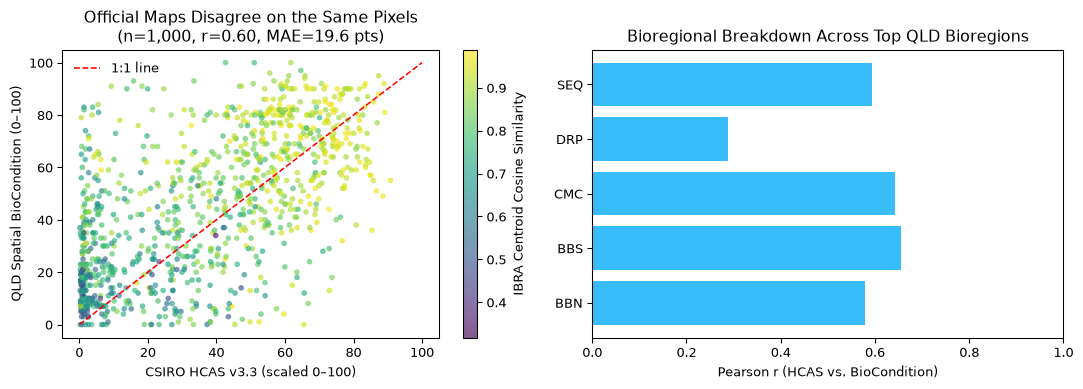

In [2]:
USE_GEE = False  # Set True if authenticated with Google Earth Engine

if USE_GEE:
    import ee
    ee.Initialize()  # or ee.Authenticate() first in Colab
    aoi = ee.Geometry.Rectangle([148.10, -25.12, 148.30, -24.98])  # Carnarvon Gorge transition
    ae_img = (
        ee.ImageCollection("GOOGLE/SATELLITE_EMBEDDING/V1/ANNUAL")
        .filterDate("2024-01-01", "2024-12-31")
        .filterBounds(aoi)
        .mosaic()
        .select([f"A{i:02d}" for i in range(64)])
    )
    print("GEE AlphaEarth bands ready:", ae_img.bandNames().getInfo()[:6], "...")


def dequantise_alpha_earth(raw_int8: np.ndarray) -> np.ndarray:
    '''Convert int8 AlphaEarth embeddings to unit L2-normalised float32 vectors.'''
    x = np.asarray(raw_int8, dtype=np.float32)
    deq = np.sign(x) * np.square(x / 127.5)
    norms = np.linalg.norm(deq, axis=-1, keepdims=True)
    norms = np.where(norms == 0, 1.0, norms)
    return deq / norms


with open(DATA_DIR / "reference_centroids.json", "r", encoding="utf-8") as f:
    CENTROIDS = json.load(f)

SUB_CENTROIDS = {k: np.asarray(v, dtype=np.float32) for k, v in CENTROIDS["subregion"].items()}
REG_CENTROIDS = {k: np.asarray(v, dtype=np.float32) for k, v in CENTROIDS["bioregion"].items()}
CONT_CENTROID = np.asarray(CENTROIDS["continental"], dtype=np.float32)


def compute_subregion_similarity(X_norm: np.ndarray, sub_codes, reg_codes) -> np.ndarray:
    '''Compute cosine similarity to local IBRA7 subregion (or bioregion/continental) centroid.'''
    cent_mat = np.empty((len(X_norm), 64), dtype=np.float32)
    for i, (sub, reg) in enumerate(zip(sub_codes, reg_codes)):
        if sub in SUB_CENTROIDS:
            cent_mat[i] = SUB_CENTROIDS[sub]
        elif reg in REG_CENTROIDS:
            cent_mat[i] = REG_CENTROIDS[reg]
        else:
            cent_mat[i] = CONT_CENTROID
    return np.sum(X_norm * cent_mat, axis=1, dtype=np.float32)


df_pts = pd.read_parquet(DATA_DIR / "sample_public_points.parquet")
emb_cols = [f"a{i:02d}" for i in range(64)]
X_norm = dequantise_alpha_earth(df_pts[emb_cols].values)
sim_ref = compute_subregion_similarity(X_norm, df_pts["sub_code_7"].values, df_pts["reg_code_7"].values)
X_65d = np.column_stack([X_norm, sim_ref]).astype(np.float32)

print(f"Loaded {len(df_pts):,} public sample points | Feature matrix shape: {X_65d.shape}")
print("Strata breakdown:", df_pts["stratum"].value_counts().to_dict())

# Visualize Act 1: Why HCAS (intactness) and Spatial BioCondition (structure) disagree
df_ov = df_pts[df_pts["stratum"] == "overlap"].copy()
r_raw, _ = stats.pearsonr(df_ov["hcas"] * 100.0, df_ov["sbc_score"])
mae_raw = mean_absolute_error(df_ov["sbc_score"], df_ov["hcas"] * 100.0)

fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.2))
sc = axes[0].scatter(df_ov["hcas"] * 100.0, df_ov["sbc_score"], c=sim_ref[df_pts["stratum"] == "overlap"],
                     cmap="viridis", alpha=0.65, s=18, edgecolors="none")
axes[0].plot([0, 100], [0, 100], "r--", lw=1.2, label="1:1 line")
axes[0].set_xlabel("CSIRO HCAS v3.3 (scaled 0–100)")
axes[0].set_ylabel("QLD Spatial BioCondition (0–100)")
axes[0].set_title(f"Official Maps Disagree on the Same Pixels\n(n={len(df_ov):,}, r={r_raw:.2f}, MAE={mae_raw:.1f} pts)")
axes[0].legend(frameon=False)
plt.colorbar(sc, ax=axes[0], label="IBRA Centroid Cosine Similarity")

top_regs = df_ov["reg_code_7"].value_counts().head(8).index
reg_corrs = [stats.pearsonr(g["hcas"] * 100.0, g["sbc_score"])[0]
             for _, g in df_ov[df_ov["reg_code_7"].isin(top_regs)].groupby("reg_code_7")]
reg_names = [r for r, _ in df_ov[df_ov["reg_code_7"].isin(top_regs)].groupby("reg_code_7")]
axes[1].barh(reg_names, reg_corrs, color="#38BDF8")
axes[1].set_xlabel("Pearson r (HCAS vs. BioCondition)")
axes[1].set_title("Bioregional Breakdown Across Top QLD Bioregions")
axes[1].set_xlim(0, 1.0)
plt.tight_layout()
plt.show()


## Part 2 · Building & Training the 4-Head Multi-Task Model (`QuadTaskDNN`)

Rather than forcing one scalar metric to represent both structural biomass and relative intactness, `ParametricQuadTaskDNN` shares a `65 -> 768 -> 384` ReLU trunk across **four specialized public heads**:
- **Head 1 (`sbc_head`):** Queensland Spatial BioCondition (`0–100`, Huber loss $\delta = 8.58$, weight `1.0`)
- **Head 2 (`hcas_head`):** Harmonized CSIRO HCAS (`0–100`, MSE loss, weight `0.151`)
- **Head 3 (`ref_head`):** Reference Climax Fidelity (logits, BCE loss $\times 100$, weight `0.065`)
- **Head 4 (`nat_head`):** Floristic Nativity / UN SEEA-EA ECS from HAVPlot + WorldCover negatives (`0–100`, Huber loss $\delta = 7.93$, weight `0.215`)

Notice two critical lessons from the talk:
1. **Spatially Blocked Split:** We hold out `spatial_fold == 2` (100 km spatial blocks / IBRA subregions) rather than a random row split.
2. **Unweighted Multi-Task Validation Score:** Hyperparameter search evaluates the **unweighted** sum $\mathcal{L}_{\mathrm{sbc}} + \mathcal{L}_{\mathrm{hcas}} + \mathcal{L}_{\mathrm{ref}} + \mathcal{L}_{\mathrm{nat}}$ so an optimiser cannot cheat by shrinking the multiplier of a harder task.


Epoch  1/50 | Train Weighted=468.30 | Val Unweighted=1271.71 (SBC=124.3, HCAS=893.7, Ref=69.2, Nat=184.5)


Epoch 15/50 | Train Weighted=152.87 | Val Unweighted=606.09 (SBC=82.1, HCAS=346.5, Ref=37.0, Nat=140.5)


Epoch 30/50 | Train Weighted=133.68 | Val Unweighted=553.05 (SBC=83.6, HCAS=300.9, Ref=32.7, Nat=135.8)


Epoch 50/50 | Train Weighted=126.40 | Val Unweighted=552.49 (SBC=82.3, HCAS=302.4, Ref=32.6, Nat=135.2)

Held-Out Spatial Fold Validation (trained solely on 2,003-row mini-corpus):
  Head 1 BioCondition: r=0.775, MAE=13.3
  Head 2 HCAS:         r=0.833, MAE=13.4
  Head 3 Ref Climax:   ROC-AUC=0.955
  Head 4 Nativity:     r=0.572, MAE=20.7


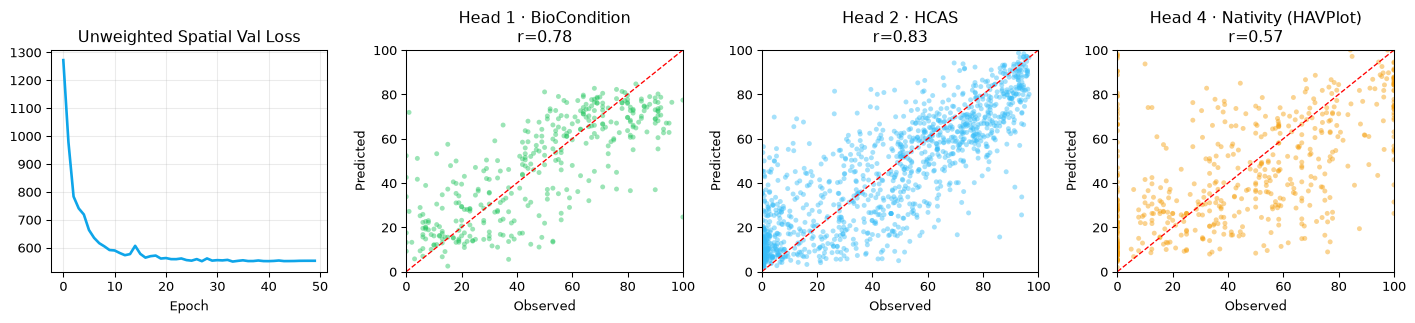

In [3]:
class ParametricQuadTaskDNN(nn.Module):
    def __init__(self, input_dim=65, layers_config=(768, 384), activation="relu",
                 dropout_rate=0.1362, head_type="subhead_light", head_dropout=0.1297):
        super().__init__()
        act_cls = {"relu": nn.ReLU, "gelu": nn.GELU, "silu": nn.SiLU}[activation.lower()]
        layers = []
        prev_dim = input_dim
        for h_dim in layers_config:
            layers.extend([nn.Linear(prev_dim, h_dim), act_cls(), nn.Dropout(dropout_rate)])
            prev_dim = h_dim
        self.backbone = nn.Sequential(*layers)

        self.sbc_head = nn.Linear(prev_dim, 1)
        sub_dim = 64 if head_type == "subhead_light" else 128
        self.hcas_head = nn.Sequential(nn.Linear(prev_dim, sub_dim), act_cls(), nn.Dropout(head_dropout), nn.Linear(sub_dim, 1))
        self.ref_head = nn.Sequential(nn.Linear(prev_dim, sub_dim), act_cls(), nn.Dropout(head_dropout), nn.Linear(sub_dim, 1))
        self.nat_head = nn.Sequential(nn.Linear(prev_dim, sub_dim), act_cls(), nn.Dropout(head_dropout), nn.Linear(sub_dim, 1))

    def forward(self, x):
        feat = self.backbone(x)
        sbc_pred = self.sbc_head(feat).squeeze(-1) * 100.0
        hcas_pred = self.hcas_head(feat).squeeze(-1)
        ref_logits = self.ref_head(feat).squeeze(-1)
        nat_pred = self.nat_head(feat).squeeze(-1) * 100.0
        return sbc_pred, hcas_pred, ref_logits, nat_pred


class MaskedQuadTaskLoss(nn.Module):
    def __init__(self, w_sbc=1.0, w_hcas=0.1510, w_ref=0.0648, w_nat=0.2151,
                 huber_delta=8.579, huber_delta_nat=7.931):
        super().__init__()
        self.w_sbc, self.w_hcas, self.w_ref, self.w_nat = w_sbc, w_hcas, w_ref, w_nat
        self.huber_sbc = nn.HuberLoss(delta=huber_delta, reduction="none")
        self.huber_nat = nn.HuberLoss(delta=huber_delta_nat, reduction="none")
        self.mse = nn.MSELoss(reduction="none")
        self.bce = nn.BCEWithLogitsLoss(reduction="none")

    def forward(self, sbc_pred, hcas_pred, ref_logits, nat_pred,
                sbc_true, hcas_true, ref_true, nat_true,
                has_sbc, has_hcas, has_ref, has_nat):
        l_sbc = self.huber_sbc(sbc_pred[has_sbc], sbc_true[has_sbc]).mean() if has_sbc.any() else torch.tensor(0.0, device=sbc_pred.device)
        l_hcas = self.mse(hcas_pred[has_hcas] * 100.0, hcas_true[has_hcas] * 100.0).mean() if has_hcas.any() else torch.tensor(0.0, device=hcas_pred.device)
        l_ref = (self.bce(ref_logits[has_ref], ref_true[has_ref]) * 100.0).mean() if has_ref.any() else torch.tensor(0.0, device=ref_logits.device)
        l_nat = self.huber_nat(nat_pred[has_nat], nat_true[has_nat]).mean() if has_nat.any() else torch.tensor(0.0, device=nat_pred.device)
        weighted = self.w_sbc * l_sbc + self.w_hcas * l_hcas + self.w_ref * l_ref + self.w_nat * l_nat
        unweighted = l_sbc + l_hcas + l_ref + l_nat
        return weighted, unweighted, (l_sbc.item(), l_hcas.item(), l_ref.item(), l_nat.item())


# Prepare spatially blocked train/validation tensors
train_mask = (df_pts["spatial_fold"].values != 2)
val_mask = ~train_mask

def make_tensors(mask):
    sub = df_pts[mask]
    return (
        torch.from_numpy(X_65d[mask]),
        torch.from_numpy(np.nan_to_num(sub["sbc_score"].values, nan=0.0).astype(np.float32)),
        torch.from_numpy(np.nan_to_num(sub["hcas"].values, nan=0.5).astype(np.float32)),
        torch.from_numpy(np.nan_to_num(sub["ref_target"].values, nan=0.0).astype(np.float32)),
        torch.from_numpy(np.nan_to_num(sub["nat_target"].values, nan=0.0).astype(np.float32)),
        torch.from_numpy(sub["has_sbc"].values.astype(bool)),
        torch.from_numpy(sub["has_hcas"].values.astype(bool)),
        torch.from_numpy(sub["has_ref"].values.astype(bool)),
        torch.from_numpy(sub["has_nat"].values.astype(bool)),
    )

tr_tensors = make_tensors(train_mask)
va_tensors = make_tensors(val_mask)
tr_loader = DataLoader(TensorDataset(*tr_tensors), batch_size=256, shuffle=True)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
with open(DATA_DIR / "quadtask_v2_metadata.json") as f:
    hp = json.load(f)["hyperparameters"]

demo_model = ParametricQuadTaskDNN(
    layers_config=(hp["h1_2l"], hp["h2_2l"]),
    activation=hp["activation"],
    dropout_rate=hp["dropout_rate"],
    head_type=hp["head_type"],
    head_dropout=hp["head_dropout"],
).to(device)
criterion = MaskedQuadTaskLoss(
    w_hcas=hp["w_hcas"], w_ref=hp["w_ref"], w_nat=hp["w_nat"],
    huber_delta=hp["huber_delta"], huber_delta_nat=hp["huber_delta_nat"],
)
optimizer = torch.optim.AdamW(demo_model.parameters(), lr=hp["lr"], weight_decay=hp["weight_decay"])
EPOCHS = 50
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=EPOCHS)

history = {"tr_weighted": [], "va_unweighted": []}
for ep in range(1, EPOCHS + 1):
    demo_model.train()
    tr_losses = []
    for bx, bsbc, bhcas, bref, bnat, hs, hh, hr, hn in tr_loader:
        bx, bsbc, bhcas, bref, bnat = [t.to(device) for t in (bx, bsbc, bhcas, bref, bnat)]
        hs, hh, hr, hn = [t.to(device) for t in (hs, hh, hr, hn)]
        optimizer.zero_grad()
        ps, ph, pr, pn = demo_model(bx)
        w_loss, _, _ = criterion(ps, ph, pr, pn, bsbc, bhcas, bref, bnat, hs, hh, hr, hn)
        w_loss.backward()
        optimizer.step()
        tr_losses.append(w_loss.item())
    scheduler.step()

    demo_model.eval()
    with torch.no_grad():
        vx, vsbc, vhcas, vref, vnat, vhs, vhh, vhr, vhn = [t.to(device) for t in va_tensors]
        vps, vph, vpr, vpn = demo_model(vx)
        _, va_unw, comp = criterion(vps, vph, vpr, vpn, vsbc, vhcas, vref, vnat, vhs, vhh, vhr, vhn)
    history["tr_weighted"].append(float(np.mean(tr_losses)))
    history["va_unweighted"].append(float(va_unw.item()))
    if ep in (1, 15, 30, 50):
        print(f"Epoch {ep:2d}/{EPOCHS} | Train Weighted={history['tr_weighted'][-1]:.2f} | "
              f"Val Unweighted={va_unw.item():.2f} (SBC={comp[0]:.1f}, HCAS={comp[1]:.1f}, Ref={comp[2]:.1f}, Nat={comp[3]:.1f})")

# Evaluate held-out spatial fold metrics
vps_np = np.clip(vps.cpu().numpy(), 0, 100)
vph_np = np.clip(vph.cpu().numpy() * 100.0, 0, 100)
vpr_np = 1.0 / (1.0 + np.exp(-vpr.cpu().numpy()))
vpn_np = np.clip(vpn.cpu().numpy(), 0, 100)

m_sbc = vhs.cpu().numpy()
m_hcas = vhh.cpu().numpy()
m_ref = vhr.cpu().numpy() & ((vref.cpu().numpy() == 0.0) | (vref.cpu().numpy() == 1.0))
m_nat = vhn.cpu().numpy()

print(f"\nHeld-Out Spatial Fold Validation (trained solely on {int(train_mask.sum()):,}-row mini-corpus):")
print(f"  Head 1 BioCondition: r={stats.pearsonr(vsbc.cpu().numpy()[m_sbc], vps_np[m_sbc])[0]:.3f}, MAE={mean_absolute_error(vsbc.cpu().numpy()[m_sbc], vps_np[m_sbc]):.1f}")
print(f"  Head 2 HCAS:         r={stats.pearsonr(vhcas.cpu().numpy()[m_hcas]*100, vph_np[m_hcas])[0]:.3f}, MAE={mean_absolute_error(vhcas.cpu().numpy()[m_hcas]*100, vph_np[m_hcas]):.1f}")
print(f"  Head 3 Ref Climax:   ROC-AUC={roc_auc_score(vref.cpu().numpy()[m_ref], vpr_np[m_ref]):.3f}")
print(f"  Head 4 Nativity:     r={stats.pearsonr(vnat.cpu().numpy()[m_nat], vpn_np[m_nat])[0]:.3f}, MAE={mean_absolute_error(vnat.cpu().numpy()[m_nat], vpn_np[m_nat]):.1f}")

fig, axes = plt.subplots(1, 4, figsize=(15, 3.5))
axes[0].plot(history["va_unweighted"], label="Val Unweighted Loss", color="#0EA5E9", lw=2)
axes[0].set_title("Unweighted Spatial Val Loss")
axes[0].set_xlabel("Epoch")
axes[0].grid(alpha=0.25)

for ax, yt, yp, title, col in [
    (axes[1], vsbc.cpu().numpy()[m_sbc], vps_np[m_sbc], "Head 1 · BioCondition", "#22C55E"),
    (axes[2], vhcas.cpu().numpy()[m_hcas] * 100.0, vph_np[m_hcas], "Head 2 · HCAS", "#38BDF8"),
    (axes[3], vnat.cpu().numpy()[m_nat], vpn_np[m_nat], "Head 4 · Nativity (HAVPlot)", "#F59E0B"),
]:
    ax.scatter(yt, yp, alpha=0.45, s=14, color=col, edgecolors="none")
    ax.plot([0, 100], [0, 100], "r--", lw=1)
    ax.set_xlim(0, 100); ax.set_ylim(0, 100)
    ax.set_xlabel("Observed"); ax.set_ylabel("Predicted")
    ax.set_title(f"{title}\nr={stats.pearsonr(yt, yp)[0]:.2f}")
plt.tight_layout()
plt.show()


## Part 3 · 80 m Landscape Inference with the Full-Corpus 4-Head ONNX Model

In production, `ParametricQuadTaskDNN` was trained on **4.33 million points** across all 86 Australian IBRA bioregions (using strictly the 4 public heads—no grazing Land Condition or Canopy Cover data) and exported to a self-contained `1.7 MB` ONNX graph (`quadtask_v2_4head.onnx`).

Below we load `sample_ae_chip_carnarvon.npz` (`128 × 128` 80 m pixels across **Carnarvon Gorge & Buckland Basalts, QLD**), build the 65-D input tensor with the IBRA subregion centroid LUT, and render all 4 aligned maps side-by-side.


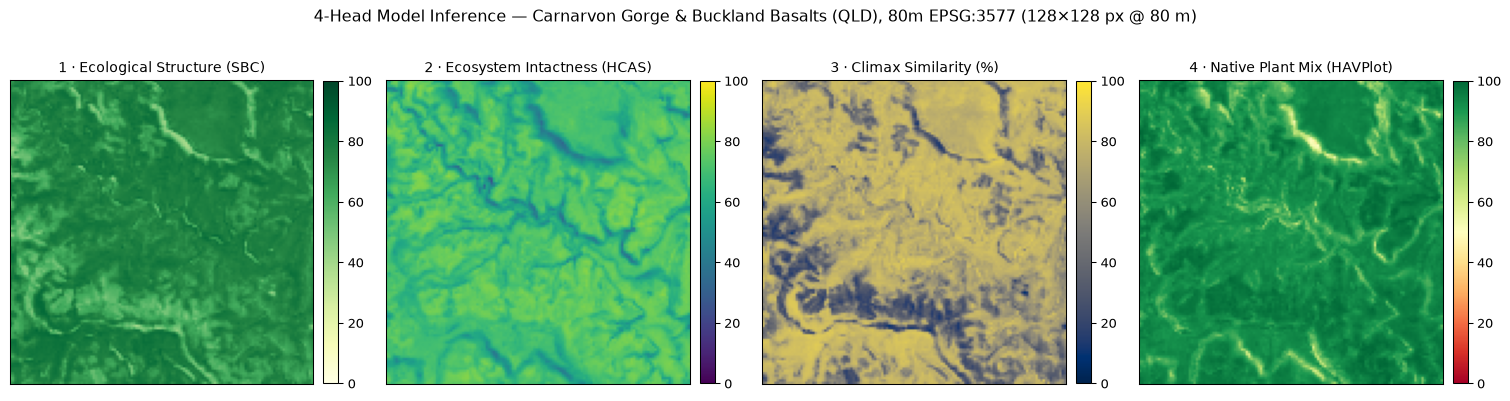

In [4]:
chip = np.load(DATA_DIR / "sample_ae_chip_carnarvon.npz")
ae_int8 = chip["ae_int8"]          # (64, 128, 128)
ibra_ids = chip["ibra_sub_id"]     # (128, 128)
sub_map = json.loads(str(chip["ibra_sub_map_json"]))
extent = chip["extent_epsg3577"]
region_title = str(chip["region_name"])

H, W = ibra_ids.shape
ae_flat = np.moveaxis(ae_int8, 0, -1).reshape(-1, 64)
X_chip_norm = dequantise_alpha_earth(ae_flat)

sub_codes_chip = [sub_map.get(str(int(sid)), {}).get("sub_code_7", "") for sid in ibra_ids.ravel()]
reg_codes_chip = [sub_map.get(str(int(sid)), {}).get("reg_code_7", "") for sid in ibra_ids.ravel()]
sim_chip = compute_subregion_similarity(X_chip_norm, sub_codes_chip, reg_codes_chip)
X_chip_65d = np.column_stack([X_chip_norm, sim_chip]).astype(np.float32)

sess = ort.InferenceSession(str(DATA_DIR / "quadtask_v2_4head.onnx"), providers=["CPUExecutionProvider"])
o_sbc, o_hcas, o_ref_logits, o_nat = sess.run(None, {"embedding_and_benchmark_65d": X_chip_65d})

band1_sbc = np.clip(o_sbc.reshape(H, W), 0.0, 100.0)
band2_hcas = np.clip(o_hcas.reshape(H, W) * 100.0, 0.0, 100.0)
band3_ref = (1.0 / (1.0 + np.exp(-o_ref_logits.reshape(H, W)))) * 100.0
band4_nat = np.clip(o_nat.reshape(H, W), 0.0, 100.0)

fig, axes = plt.subplots(1, 4, figsize=(16, 4.2), sharex=True, sharey=True)
panels = [
    (band1_sbc, "1 · Ecological Structure (SBC)", "YlGn"),
    (band2_hcas, "2 · Ecosystem Intactness (HCAS)", "viridis"),
    (band3_ref, "3 · Climax Similarity (%)", "cividis"),
    (band4_nat, "4 · Native Plant Mix (HAVPlot)", "RdYlGn"),
]
for ax, (arr, title, cmap) in zip(axes, panels):
    im = ax.imshow(arr, vmin=0, vmax=100, cmap=cmap, extent=extent)
    ax.set_title(title, fontsize=10.5)
    ax.set_xticks([]); ax.set_yticks([])
    plt.colorbar(im, ax=ax, fraction=0.046, pad=0.03)
fig.suptitle(f"4-Head Model Inference — {region_title} (128×128 px @ 80 m)", fontsize=12, y=1.02)
plt.tight_layout()
plt.show()


## Part 4 · Verb-Driven Process Analysis (`PROMPT_V5_REFINED`)

> *This work is inspired by verb-centred grammar. It does **not** represent or speak for First Nations knowledge. It looks at how verb-centred and noun-centred languages frame environmental processes differently—contrasting a static checklist view against a process view.*

Instead of asking a Vision-Language Model for static noun tallies (`biomass`, `ground cover`, `gully`), **`PROMPT_V5_REFINED`** (inlined below):
1. Masks foreground roads, verges, and vehicle frames (`30–100 m` interior projection).
2. Grounded in bioregion & antecedent rainfall (`Decile` + `Cumulative Rainfall Anomaly`), enforces **Phase 1 noun blocking** across 4 coupled physical planes (*Subterranean*, *Earth-and-Water*, *Canopy/Air/Understory*, *Fire & Disturbance-Renewal*).
3. Separates active verbs into **Holding (`Care`)** vs. **Losing (`Rupture`)** across 5 morphosyntactic verb families (preventing *kinetic conflation*) with strict cultural-safety guardrails (zero ventriloquism, zero sacred-term extraction).

Below, the prompt and Phase 1 rubric validator are embedded directly in the notebook. If `GEMINI_API_KEY` is available (via Colab Secrets or environment variable), it queries Gemini live on the bundled talk photos; otherwise it seamlessly loads the cached `PROMPT_V5_REFINED` outputs for inspection.


In [5]:
PROMPT_V5_REFINED = """You are reading landscapes across an ecological transect spanning southern and western Queensland, from South East Queensland subcoastal valleys, through the Brigalow Belt and Carnarvon Sandstone Gorges, across the Mitchell Grass Downs and Mulga Lands, to the Barcoo and Diamantina Channel Country and stony gibber tablelands.

Conduct your analysis using a **Process-Relational & Animacy Grammar** (informed by cognitive linguistics, thermodynamic source-sink ecology, and holistic landscape systems science, without impersonating an Indigenous Elder, claiming Traditional Owner authority, or appropriating sacred ethnographic terms). Rather than treating the landscape as an inert collection of static nouns or accounting checklist items, read the site as a **single coupled, living, self-organising system** whose vitality depends on continuous movement, circulation, and reciprocal feedback across **four coupled relational planes**:
1. **The Subterranean Plane** (root networks, deep soil-moisture vaults, and underground breathing pathways moving `Root-ward` and `Deep-water-ward`)
2. **The Earth-and-Water Plane** (the living surface skin, self-mulching clay fissures, or interlocking stone pavements receiving and holding rain `Surface-deep` versus shedding, scouring, or losing soil `Downslope-ward`, `Channel-ward`, and `Outflow-ward`)
3. **The Canopy, Air, and Understory Plane** (perennial ground-layer tussocks, hummocks, and chenopods sheltering the floor; midstory shrubs filtering wind; and mature overstory trees shading and cooling `Sun-ward`, `Shadow-ward`, `Sky-ward`, and `Horizon-ward` — or naturally open treeless horizons on cracking-clay downs and gibber plains)
4. **The Fire and Disturbance-Renewal Plane** (low-intensity mosaic fire processes moving `Smoke-ward` and `Ash-ward`, cycling aged thatch into mineral ash and maintaining open midstory spacing versus fire-excluded woody thickening, suffocating thatch accumulation, or mechanical windrow/tillage scarring)

### SITE & ANTECEDENT CLIMATE CONTEXT
- **Station ID**: {site_id} ({photo_count} field photograph(s): {basenames_str})
- **Capture Timestamp**: {date}
- **Geographic / Bioregional Context**: {region} | IBRA Region: {ibra_region} | IBRA Subregion: {ibra_subregion}
- **Antecedent Rainfall Context**: Rainfall Decile {decile} (Cumulative Rainfall Anomaly: {cra_value} mm; Trend: {cra_trend})

---

### CRITICAL SPATIAL, THERMODYNAMIC & CULTURAL SAFETY DIRECTIVES

1. **Roadside / Foreground Masking & Vehicle Exclusion**:
   - Many photographs are captured from a vehicle or road corridor looking out into the paddock.
   - **Completely ignore** any vehicle mirrors, window frames, bullbars, bitumen, graded gravel shoulders, table drains, and fence lines in the immediate foreground.
   - Project your reading **30m–100m past the fence line or road verge into the true landscape interior**. Set `"road_verge_masked_flag": true` in the JSON if a road verge, fence line, wheel track, or vehicle part is visible in the frame, and explicitly state how you looked past it.

2. **Bioregional Baselines vs. Ephemeral Climate Friction**:
   - **Open Cracking-Clay Downs** (*Mitchell Grass Downs*) and **Stony Gibber & Chenopod Tablelands** (*Channel Country*) are **naturally treeless or sparse** by evolutionary bioregional baseline. An open horizon without trees in these bioregions represents an intact **`Reciprocal / Self-Sustaining`** baseline, NOT "amputated canopy" or "cleared forest".
   - **Gibber pavements** (dense red ironstone pebbles) act as natural **protective stone armour** (`pebble-locking`) holding moisture beneath and preventing wind scouring; do NOT misdiagnose intact gibber pavement as "bare scalded ground".
   - **Channel Country floodways & billabongs** naturally carry creamy, clay-rich turbid waters that nourish deep cracking clays; turbidity here is vital nutrient-rich clay suspension, not degradation.
   - **Sandstone Gorges & Basalt Escarpments** (*Carnarvon*) have natural cliff faces and rocky talus that provide structural shelter and cool thermal refugia.
   - **Seasonal Ephemeral Flush Masking on Red-Earth Mulga/Box Plains (`Inverted / Masked`, `2.5–5.2`, `decoupling_detected: true`)**: In `Red Earth Mulga & Box Woodland` (such as West Bulloo / Mulga Lands plains), Decile 9–10 winter rain can trigger a lush carpet of short-lived annual daisies and pioneer copperburrs. Look carefully beneath the seasonal bloom: if the central plain has lost its mature Mulga/Box overstory and midstory shrubs (leaving only isolated bleached dead stags with zero sapling recruitment), and exhibits a persistent hard-set bare red pan (`~10–20%`) or wheel tracks deflecting sheetflow, do NOT classify it as `Reciprocal / Self-Sustaining`! Diagnose it as **`Inverted / Masked` (`2.8 – 4.2`, with secondary `Reciprocal / Self-Sustaining`, `decoupling_detected: true`)** because ephemeral winter herbs temporarily mask structural woodland simplification and localised surface sealing.
   - **Pulled Brigalow / Mulga Windrows & Mechanically Ploughed Cropping Paddocks**: Piled dead timber windrows (`FN_SITE_120` style) or freshly ploughed bare fallow soil (`FN_SITE_132` style) represent acute mechanical disruption (`Kinetically Disrupted / Thicket-Locked` or `Acutely Ruptured / Wounded`), even if Western pasture/cropping metrics see "high woody debris" or "prepared seedbed".

3. **Thermodynamic Retention vs. Dissipation Physics (Preventing Kinetic Conflation)**:
   - Never confuse high-energy destructive mass transfer (e.g., rapid sheet-stripping, gullying, wind-winnowing, or aggressive invasive monoculture spreading) with ecological vitality simply because it is kinetically active.
   - Ground every verb in **thermodynamic source-sink conservation physics**:
     - **Verbs of Care (Retention, Interception & Reciprocal Buffering Fluxes)**: Processes that slow kinetic energy, intercept and sink rainfall `Surface-deep` and `Root-ward`, knit soil aggregates, and buffer thermal extremes.
     - **Verbs of Rupture (Dissipation, Export & Structural Rupture Fluxes)**: Processes that accelerate overland loss of soil and water `Downslope-ward` and `Outflow-ward`, seal or smear the surface skin, sever vertical root-canopy coupling, or choke midstory/understory renewal.

4. **Strict Phase 1 Grammatical & Cultural Safety Guardrail (Verb Creativity, Zero Clinical Nouns, Zero Sacred/Tokenistic Extraction)**:
   - In **Phase 1 (`### Relational Deliberation`) ONLY**, conceptualise the landscape through **Active Process Verbs**, **Resultative Verb Compounds**, **Relational Verb Chains**, and **Sociotopographic Vectors**.
   - **Creative Verb Diversity Across Five Morphosyntactic Families**: Select vivid, landform-specific process verbs tailored to the exact soil physics, geology, and disturbance mechanics visible in the photograph, drawing across all five verb families:
     1. *Inchoative / State-Transition verbs* (e.g., softening, crusting, awakening, closing, calcifying, greening, germinating, hardening, hard-setting, bleaching, opening, withering, sealing, swelling, fissuring, caking, coppicing, suckering)
     2. *Reciprocal / Co-active verbs* (e.g., co-sheltering, answering, trading, nursing, leaning, buffering, sharing, sheltering, nourishing, sustaining, yielding, quieting, baffling, arch-shading, canopy-filtering, damping)
     3. *Hydrological / Kinetic & Resultative verbs* (e.g., percolating, slaking, clod-slaking, fissure-drinking, cradling, winnowing, wind-winnowing, sheet-stripping, scouring, rill-incising, unzipping, soaking, drinking, sinking, channelling, shedding, sheeting, flushing, gullying, pugging, splashing, leaching, pooling, seeping, weeping, wicking, condensing, guttering, incising)
     4. *Structural / Somatic & Resultative verbs* (e.g., knitting, root-knitting, anchoring, threading, throttling, ringbarking, windrowing, scalping, weaving, binding, interlocking, stitching, rooting, amputating, severing, ripping, ploughing, uprooting, crushing, thicket-locking, smothering, choking, wedging, buttressing, pebble-locking, matting, muffling, inverting, wrenching, smearing, pan-smearing)
     5. *Rhythmic / Thermal verbs* (e.g., pulsing, exhaling, tempering, parching, resting, cycling, breathing, cooling, baking, scalding, recharging, renewing, desiccating, searing)
   - **STRICTLY FORBIDDEN in Phase 1 (Static Clinical & Survey Nouns)**: Never use static clinical nouns in Phase 1: `biomass`, `fuel load`, `stratum`, `strata`, `litter`, `microclimate`, `canopy cover`, `ground cover`, `basal area`, `forb`, `graminoid`, `senescent`, `tussock crown`, `macropore`, `infiltration`, `pedestal`, `rill`, `scald`, `scalds`, `aeration`, `transpiration`, `evapotranspiration`, `photosynthesis`, `hydrology`, `hydrological`, `carbon`, `nitrogen`, `mycorrhizal`, `mycorrhizae`, `fungal`, `fungi`, `hyphae`, `rhizosphere`, `aquifer`, `water table`, `bulk density`, `porosity`, `compaction`, `organic matter`, `humus`, `nutrient cycling`, `pyrodiversity`, `fire regime`, `fuel moisture`, `erosion`, `gully`, `gullies`, `sheet wash`, `coarse woody debris`, `3P grasses`, `floristic nativity`, `BioCondition`, `sediment`, `bare ground`, `dry matter`, `monoculture`, `monocultural`, `stubble`, `hectare`, `hectares`, `transect`, `transects`. Never write literal meta-phrases like `"VERB-active"`.
   - **STRICTLY FORBIDDEN Across the Entire Response (Zero Digital Ventriloquism, Zero Sacred Vernacular Extraction, Zero Stylistic Tokenism)**:
     - Never impersonate an Indigenous Elder or Traditional Owner, and never invoke sacred/ceremonial concepts (`Dreaming`, `Dreamtime`, `Songlines`, `sacred Law`, `ancient Law`).
     - Never extract or output sacred/ethnographic vernacular (`Sorry Country`, `is_sorry_country`, `Sorry / Hurting`, `Quiet / Nourishing`, `Upside-Down / Sick`, `Wild / Disorganised`, `Ancestral Fire Plane`, `ancestral_fire`, `cultural_fire_prescription`) anywhere in prose or JSON keys.
     - Never use synthetic hyphenated tokenism (`root-kin`, `grass-kin`, `shrub-kin`, `ground-kin`, `ant-kin`, `leaf-gift`, `ash-gift`, `sky-gift`, `earth-belly`) or metaphorical `elder` compounds (`tree elders`, `tussock elders`, `woodland elders`, `senior elders`). Express animacy strictly through **verb morphology and ecological process syntax**, not pseudo-Indigenous compound nouns.
   - *(Note: In Phases 2, 3, 4, and 5, you MAY and SHOULD use standard Western ecological terms when explicitly contrasting process-relational reading against Western BioCondition and ABCD frameworks.)*

---

### REQUIRED FIVE-PHASE STRUCTURE

#### `### Relational Deliberation`
Read the landscape holistically as a single coupled system across five paragraphs introduced by bold inline titles (do NOT use `###` or `####` sub-headings inside this section, and do NOT use any banned clinical nouns or tokenistic/sacred terms):
- **1. The Subterranean Plane**: Trace the underground processes moving `Root-ward` and `Deep-water-ward` across root architectures, deep moisture vaults, and soil-breathing pathways, choosing verbs specific to this substrate (e.g. sandstone seams, cracking vertosols, red hardpan, alluvial clays, or mechanically ploughed clods).
- **2. The Earth-and-Water Plane**: Trace how the surface skin or stone pavement is interacting with rain, wind, and overland movement `Surface-deep`, `Downslope-ward`, `Channel-ward`, and `Outflow-ward`, distinguishing retention fluxes from dissipation fluxes.
- **3. The Canopy, Air, and Understory Plane**: Trace how ground-layer plants, midstory shrubs, and mature overstory trees (or naturally open treeless horizons on downs and gibber plains) are interacting `Sun-ward`, `Shadow-ward`, `Sky-ward`, and `Horizon-ward`.
- **4. The Fire and Disturbance-Renewal Plane**: Trace how thermal, disturbance, and renewal processes are moving `Smoke-ward` and `Ash-ward` (whether low-intensity mosaic fire cycling, naturally fire-free refugia, fire-excluded thatch/thicket choking, or mechanical windrow/tillage disruption).
- **5. Cross-Plane Organismal Coupling**: Synthesise how these four planes are acting upon one another right now as a **single coupled system**, tracing the exact causal flow of moisture, shade, energy, or disruption across planes without using any banned Phase 1 nouns.

#### `### Affective & Systemic State: How is the Landscape Holding Together?`
Diagnose the landscape's holistic systemic state and assign a **continuous float `somatic_trauma_score` (`0.0` to `10.0`, to one decimal place)** calibrated strictly to these four process-systemic regimes:
- **`Reciprocal / Self-Sustaining` (`0.0 – 2.4`, `is_acutely_ruptured: false`)**: All four planes operate in reciprocal, self-sustaining balance (`0.0–1.2` intact woodland/downs/gibber/billabong; `1.3–2.4` mostly balanced with mild seasonal dry stress or light aged thatch).
- **`Inverted / Masked` (`2.5 – 5.2`, `is_acutely_ruptured: false`)**: Structural or floristic inversion *without* widespread active bare-soil scouring or mechanical timber heaps. Examples: cleared subcoastal or woodland paddocks where overstory trees are removed/stranded (`canopy_and_air` trauma high), seasonal wildflower flushes masking a persistent localised hard-set pan and missing woodland overstory (`FN_SITE_102` style), or unburned exotic pasture/thatch locking up the understorey (`fire_and_renewal` trauma elevated), while ground cover keeps most of the `earth_and_water` and `subterranean` planes physically stable.
- **`Kinetically Disrupted / Thicket-Locked` (`5.3 – 7.4`, `is_acutely_ruptured: false`)**: Active kinetic disorder, severe fire-excluded woody thicket choking, or mechanical timber-pulling/windrowing (`FN_SITE_116`/`FN_SITE_120` style) where `fire_and_renewal` and/or `canopy_and_air` planes are heavily disrupted (`6.0–8.5`), **YET** resilient perennial ground-layer plants and subterranean roots are still actively working to stitch the surface and prevent total bare-soil collapse.
- **`Acutely Ruptured / Wounded` (`7.5 – 10.0`, `is_acutely_ruptured: true`)**: Acute physical rupture of the **Earth-and-Water** and **Subterranean** planes (`earth_and_water` and `subterranean` trauma >= 7.5): widespread hard-sealed/scalded bare ground (>60% exposed) actively shedding water, deep active gullying, or mechanical ploughing/blade-scalping (`FN_SITE_132`/`FN_SITE_54` style) that has torn open the soil surface and underground root network.

#### `### The Western Checklist Blind Spot`
Contrast your four-plane process-relational reading against Western **ABCD Grazing Land Condition (`A`, `B`, `C`, `D`)** and **Queensland BioCondition (`Class 1`, `Class 2`, `Class 3`, `Class 4`)**. Explain whether Western checklists and process-relational reading **concord** (`decoupling_detected: false`) or **decouple** (`decoupling_detected: true`), and why.

#### `### Restoring Reciprocal Balance`
Provide concrete, bioregionally grounded stewardship pathways across all four coupled planes:
1. Subterranean & Earth-Water healing (water slowing, contour brush-packing, root-network recovery).
2. Canopy, Air & Understory restoration (or protection of naturally treeless downs and gibber pavements).
3. Fire & Disturbance-Renewal stewardship (when to introduce cool mosaic fire versus when to strictly withhold fire on bare/recovering soils or naturally fire-free gibber/gorges).
4. Grazing spelling and adaptive load management.

#### `### Structured JSON Summary`
Conclude with a single valid ```json ... ``` block matching this exact culturally safe process-relational schema (in `process_verbs`, prioritise the most scene-specific, landform-diagnostic verbs and resultative compounds you generated in Phase 1 across all five verb families rather than generic stock verbs):
```json
{
  "country_bioregional_type": "<One of: Open Cracking-Clay Downs | Red Earth Mulga & Box Woodland | Brigalow & Belah Clay Scrub | Spinifex & Sandy Desert Dune | Stony Gibber & Chenopod Tableland | Channel Alluvial & Riparian Floodway | Sandstone Gorge & Basalt Eucalypt Woodland | Humid Subcoastal Grazing Valley>",
  "road_verge_masked_flag": true,
  "geographic_friction_caveat": "<1-sentence statement documenting how antecedent rainfall (Decile {decile}, CRA {cra_value} mm) interacts with or masks the long-term {ibra_subregion} structural baseline>",
  "affective_state": {
    "primary": "<One of: Reciprocal / Self-Sustaining | Inverted / Masked | Kinetically Disrupted / Thicket-Locked | Acutely Ruptured / Wounded>",
    "secondary": "<Optional secondary state from the same 4 regimes or null>",
    "is_acutely_ruptured": false,
    "somatic_trauma_score": 1.4,
    "plane_trauma_scores": {
      "subterranean": 1.0,
      "earth_and_water": 1.2,
      "canopy_and_air": 1.5,
      "fire_and_renewal": 1.8
    },
    "emotional_relational_reasoning": "<1-2 sentence synthesis of the site's holistic state across the four planes>"
  },
  "cross_plane_coupling": {
    "vertical_decoupling_tension": 0.15,
    "fire_choke_vs_bare_rupture_balance": "<float in [-1.0, +1.0]: NEGATIVE (-1.0 to -0.2) when bare-soil/scald/tillage rupture dominates (e.g. Acutely Ruptured / Wounded); near 0.0 when balanced (Reciprocal / Self-Sustaining); POSITIVE (+0.2 to +1.0) when fire-excluded thatch/thicket/windrow choking dominates>",
    "primary_cascade_direction": "<One of: Reciprocal Harmony | Top-Down (Canopy/Fire -> Earth/Root) | Bottom-Up (Soil/Root -> Canopy/Air) | Full-Organism Rupture>",
    "coupling_mechanism": "<How energy, moisture, or disruption is flowing between Subterranean, Earth-Water, Canopy-Air, and Fire-Renewal planes>"
  },
  "decoupled_strata": {
    "decoupling_detected": false,
    "decoupling_mechanism": "<Explanation of alignment or divergence between planes and Western vs process-relational reading>",
    "limiting_plane": "<One of: None (Balanced) | Subterranean | Earth-and-Water | Canopy-and-Air | Fire-and-Renewal | Multi-Plane Rupture>"
  },
  "process_verbs": {
    "care_verbs": ["<extract 6-8 distinct, scene-diagnostic retention/interception/buffering verbs used in Phase 1 spanning all 5 verb families>"],
    "rupture_verbs": ["<extract 4-6 distinct, scene-diagnostic dissipation/export/rupture verbs used in Phase 1>"],
    "sociotopographic_vectors": ["<extract all directional vectors used in Phase 1>"]
  },
  "western_checklist_paradox": {
    "estimated_western_abcd": "A",
    "estimated_biocondition_rating": "Class 1",
    "blind_spot_summary": "<Concise summary of the Western checklist blind spot or harmony>",
    "inflated_static_nouns": ["ground cover", "pasture biomass"]
  },
  "stewardship_pathway": {
    "primary_action": "<Primary stewardship action>",
    "water_slowing_strategy": "<Subterranean & Earth-Water slowing strategy>",
    "fire_and_disturbance_stewardship": "<Fire & Disturbance-Renewal plane stewardship>",
    "relational_stewardship": "<Ongoing grazing and landscape stewardship>"
  },
  "key_learnings_summary": "<1-sentence takeaway>"
}
```
"""


def fill_prompt(template: str, site: dict) -> str:
    replacements = {
        "{site_id}": str(site["site_id"]),
        "{photo_count}": "1",
        "{basenames_str}": str(site["photo_file"]),
        "{date}": str(site["datetime"]),
        "{region}": str(site["region"]),
        "{ibra_region}": str(site["ibra_region"]),
        "{ibra_subregion}": str(site["ibra_subregion"]),
        "{decile}": str(site["rainfall_decile"]),
        "{cra_value}": str(site["cra_value_mm"]),
        "{cra_trend}": str(site["cra_trend"]),
    }
    out = template
    for k, v in replacements.items():
        out = out.replace(k, v)
    return out


# Lightweight Phase-1 cultural-safety & verb-grammar rubric validator
BANNED_PHASE1_NOUNS = [
    r"\bbiomass\b", r"\bfuel\s*load(s)?\b", r"\bstratum\b", r"\bstrata\b", r"\blitter\b",
    r"\bmicroclimate\b", r"\bcanopy\s*cover\b", r"\bground\s*cover\b", r"\bbasal\s*area\b",
    r"\bforb(s)?\b", r"\bgraminoid(s)?\b", r"\bsenescent\b", r"\bmacropore(s)?\b",
    r"\binfiltration\b", r"\bpedestal(s)?\b", r"\brill(s)?\b", r"\bscald(s)?\b",
    r"\btranspiration\b", r"\bevapotranspiration\b", r"\bphotosynthesis\b", r"\bhydrology\b",
    r"\bmycorrhizal\b", r"\borganic\s*matter\b", r"\berosion\b", r"\bgully\b", r"\bgullies\b",
    r"\bsheet\s*wash\b", r"\bcoarse\s*woody\s*debris\b", r"\b3P\s*grasses\b",
    r"\bfloristic\s*nativity\b", r"\bBioCondition\b", r"\bsediment\b", r"\bbare\s*ground\b",
]
BANNED_ETHICAL_LEAKS = [
    r"\b[a-z]+-kin\b", r"\b[a-z]+-gift(s)?\b", r"\bearth-belly\b", r"\bDreaming\b",
    r"\bDreamtime\b", r"\bSongline(s)?\b", r"\bSorry\s+Country\b", r"\bis_sorry_country\b",
    r"\b(?:tree|tussock|woodland|canopy)\s+elder(s)?\b",
]

def check_phase1_rubric(md_text: str) -> dict:
    p1_match = re.search(r"###\s*Relational Deliberation(.*?)###\s*Affective", md_text, flags=re.DOTALL | re.IGNORECASE)
    phase1 = p1_match.group(1) if p1_match else md_text
    noun_leaks = [p for p in BANNED_PHASE1_NOUNS if re.search(p, phase1, flags=re.IGNORECASE)]
    ethical_leaks = [p for p in BANNED_ETHICAL_LEAKS if re.search(p, md_text, flags=re.IGNORECASE)]
    j_match = re.search(r"```json\s*(\{.*?\})\s*```", md_text, flags=re.DOTALL)
    parsed = json.loads(j_match.group(1)) if j_match else {}
    return {
        "phase1_noun_leaks": len(noun_leaks),
        "ethical_leaks": len(ethical_leaks),
        "care_verbs": parsed.get("process_verbs", {}).get("care_verbs", []),
        "rupture_verbs": parsed.get("process_verbs", {}).get("rupture_verbs", []),
        "regime": parsed.get("affective_state", {}).get("primary"),
        "trauma": parsed.get("affective_state", {}).get("somatic_trauma_score"),
        "planes": parsed.get("affective_state", {}).get("plane_trauma_scores", {}),
        "decoupled": parsed.get("decoupled_strata", {}).get("decoupling_detected"),
        "parsed": parsed,
    }

print(f"PROMPT_V5_REFINED loaded ({len(PROMPT_V5_REFINED):,} chars) and rubric validator ready.")


PROMPT_V5_REFINED loaded (19,015 chars) and rubric validator ready.


[FN_SITE_185] CACHED (set GEMINI_API_KEY for live call) | Regime=Reciprocal / Self-Sustaining | Trauma=1.3/10 | Decoupled=False | Phase-1 Noun Leaks=0 | Ethical Leaks=0
[FN_SITE_176] CACHED (set GEMINI_API_KEY for live call) | Regime=Inverted / Masked | Trauma=4.0/10 | Decoupled=True | Phase-1 Noun Leaks=0 | Ethical Leaks=0
[FN_SITE_54] CACHED (set GEMINI_API_KEY for live call) | Regime=Acutely Ruptured / Wounded | Trauma=8.1/10 | Decoupled=False | Phase-1 Noun Leaks=0 | Ethical Leaks=0


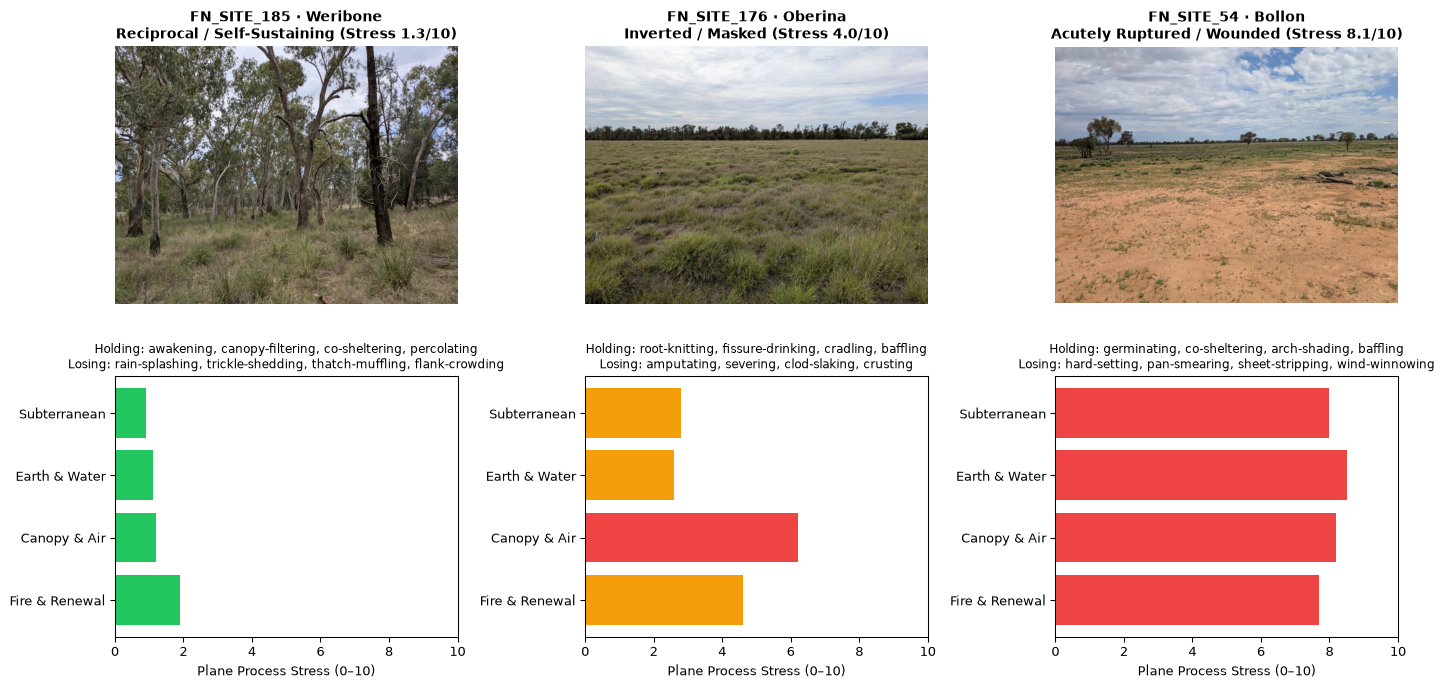

In [6]:
# Run Gemini VLM live if GEMINI_API_KEY is available, else use bundled cached PROMPT_V5_REFINED outputs
def get_gemini_api_key():
    key = os.environ.get("GEMINI_API_KEY")
    if not key:
        try:
            from google.colab import userdata
            key = userdata.get("GEMINI_API_KEY")
        except Exception:
            pass
    return key

with open(DATA_DIR / "talk_sites_context.json", "r", encoding="utf-8") as f:
    SITES = json.load(f)

GEMINI_KEY = get_gemini_api_key()
GEMINI_MODEL = "gemini-2.5-flash"  # or "gemini-2.5-pro"

site_results = []
for site in SITES:
    photo_path = PHOTO_DIR / site["photo_file"]
    if GEMINI_KEY:
        from google import genai
        client = genai.Client(api_key=GEMINI_KEY)
        img = ImageOps.exif_transpose(Image.open(photo_path))
        img.thumbnail((1536, 1536))
        resp = client.models.generate_content(model=GEMINI_MODEL, contents=[img, fill_prompt(PROMPT_V5_REFINED, site)])
        md_out = resp.text or site["cached_v5_markdown"]
        mode = f"LIVE ({GEMINI_MODEL})"
    else:
        md_out = site["cached_v5_markdown"]
        mode = "CACHED (set GEMINI_API_KEY for live call)"

    chk = check_phase1_rubric(md_out)
    site_results.append((site, photo_path, chk, mode))
    print(f"[{site['site_id']}] {mode} | Regime={chk['regime']} | Trauma={chk['trauma']}/10 | "
          f"Decoupled={chk['decoupled']} | Phase-1 Noun Leaks={chk['phase1_noun_leaks']} | Ethical Leaks={chk['ethical_leaks']}")

# Visualise the 3 sample sites: Field Photo + Holding/Losing Verbs + 4-Plane Stress
fig, axes = plt.subplots(2, 3, figsize=(15, 7.6), gridspec_kw={"height_ratios": [1.35, 1.0]})
for col, (site, photo_path, chk, _) in enumerate(site_results):
    img = ImageOps.exif_transpose(Image.open(photo_path))
    img.thumbnail((900, 900))
    axes[0, col].imshow(img)
    axes[0, col].axis("off")
    axes[0, col].set_title(f"{site['site_id']} · {site['region'].split(',')[0]}\n"
                           f"{chk['regime']} (Stress {chk['trauma']}/10)", fontsize=10.5, fontweight="bold")

    planes = chk["planes"]
    p_names = ["Subterranean", "Earth & Water", "Canopy & Air", "Fire & Renewal"]
    p_vals = [planes.get("subterranean", 0), planes.get("earth_and_water", 0),
              planes.get("canopy_and_air", 0), planes.get("fire_and_renewal", 0)]
    colors = ["#22C55E" if v < 2.5 else "#F59E0B" if v < 5.3 else "#EF4444" for v in p_vals]
    axes[1, col].barh(p_names[::-1], p_vals[::-1], color=colors[::-1])
    axes[1, col].set_xlim(0, 10)
    axes[1, col].set_xlabel("Plane Process Stress (0–10)")
    hold_txt = ", ".join(chk["care_verbs"][:4])
    lose_txt = ", ".join(chk["rupture_verbs"][:4])
    axes[1, col].set_title(f"Holding: {hold_txt}\nLosing: {lose_txt}", fontsize=8.8)

plt.tight_layout()
plt.show()


## Part 5 · Probing the Frozen `384-D` Shared Trunk (Appendix A8)

Why keep the **frozen neural trunk** (`384-D` representation) instead of only saving the 4 scalar condition maps?

1. **Higher Effective Rank:** Joint multi-task training across BioCondition, HCAS, Reference Benchmarks, and HAVPlot forces the `384-D` hidden layer to retain rich ecological variation—its SVD effective dimensionality is substantially higher than the 4 scalar outputs alone.
2. **Zero-Leakage Downstream Probing:** Freezing `model.backbone` from `quadtask_v2_4head.pt` (which has zero Land Condition or Canopy Cover supervision) lets researchers attach lightweight Ridge/Logistic probes for new local variables (such as soil surface stress or held-out ecological indicators) with minimal training data.


SVD Effective Rank — 4 Scalar Heads: 1.72 | Frozen 384-D Trunk: 32.82 (19.1× expansion)
Spatial Holdout Probe (Pure HAVPlot Botanical Plots): 3 Scalar Maps r=0.562 vs. Frozen 384-D Trunk (PCA-32) r=0.656


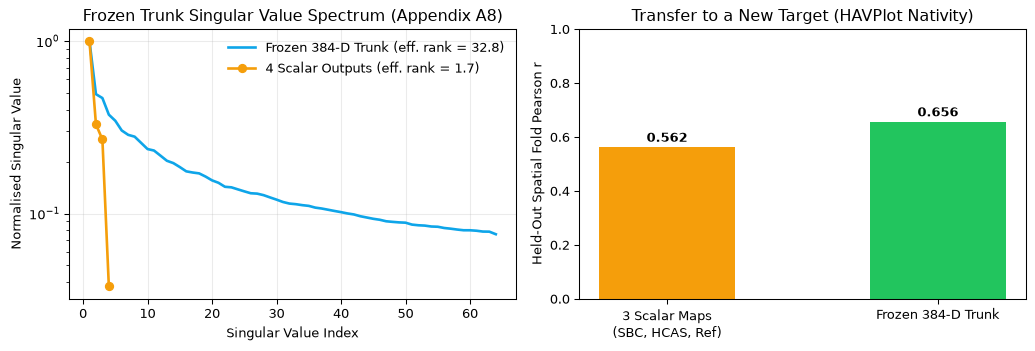

In [7]:
# Load full-corpus pretrained 4-head model and freeze the 384-D trunk
with open(DATA_DIR / "quadtask_v2_metadata.json") as f:
    meta = json.load(f)
hp = meta["hyperparameters"]

pretrained = ParametricQuadTaskDNN(
    layers_config=meta["layers_config"],
    activation=hp["activation"],
    dropout_rate=hp["dropout_rate"],
    head_type=hp["head_type"],
    head_dropout=hp["head_dropout"],
)
pretrained.load_state_dict(torch.load(DATA_DIR / "quadtask_v2_4head.pt", map_location="cpu", weights_only=True))
pretrained.eval()
for p in pretrained.backbone.parameters():
    p.requires_grad = False

with torch.no_grad():
    x_t = torch.from_numpy(X_65d)
    Z_trunk = pretrained.backbone(x_t).numpy()  # (3200, 384)
    p_sbc, p_hcas, p_ref, p_nat = pretrained(x_t)
    Y_4head = np.column_stack([p_sbc.numpy(), p_hcas.numpy() * 100.0, p_ref.numpy(), p_nat.numpy()])
    Y_3other = Y_4head[:, :3]  # Non-nativity scalar heads (SBC, HCAS, Ref)


def effective_svd_rank(M: np.ndarray):
    M_c = M - M.mean(axis=0, keepdims=True)
    _, s, _ = np.linalg.svd(M_c, full_matrices=False)
    p = (s ** 2) / np.sum(s ** 2)
    p = p[p > 1e-12]
    return float(np.exp(-np.sum(p * np.log(p)))), s


erank_trunk, sv_trunk = effective_svd_rank(Z_trunk)
erank_4head, sv_4head = effective_svd_rank(Y_4head)
print(f"SVD Effective Rank — 4 Scalar Heads: {erank_4head:.2f} | Frozen 384-D Trunk: {erank_trunk:.2f} ({erank_trunk/erank_4head:.1f}× expansion)")

# Downstream Ridge probe: predict pure HAVPlot botanical nativity from ONLY the 3 non-nativity scalar heads vs. PCA-compressed Frozen 384-D Trunk
hav_only = (df_pts["stratum"].values == "havplot_nativity")
tr_idx = hav_only & (df_pts["spatial_fold"].values != 2)
va_idx = hav_only & (df_pts["spatial_fold"].values == 2)
y_nat = df_pts["nat_target"].values

alphas = np.logspace(0, 4, 9)
probe_trunk = make_pipeline(StandardScaler(), PCA(n_components=32, random_state=42), RidgeCV(alphas=alphas)).fit(Z_trunk[tr_idx], y_nat[tr_idx])
probe_3head = make_pipeline(StandardScaler(), RidgeCV(alphas=alphas)).fit(Y_3other[tr_idx], y_nat[tr_idx])
r_trunk = stats.pearsonr(y_nat[va_idx], probe_trunk.predict(Z_trunk[va_idx]))[0]
r_3head = stats.pearsonr(y_nat[va_idx], probe_3head.predict(Y_3other[va_idx]))[0]
print(f"Spatial Holdout Probe (Pure HAVPlot Botanical Plots): 3 Scalar Maps r={r_3head:.3f} vs. Frozen 384-D Trunk (PCA-32) r={r_trunk:.3f}")

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
axes[0].semilogy(np.arange(1, 65), sv_trunk[:64] / sv_trunk[0], label=f"Frozen 384-D Trunk (eff. rank = {erank_trunk:.1f})", color="#0EA5E9", lw=2)
axes[0].semilogy(np.arange(1, 5), sv_4head / sv_4head[0], "o-", label=f"4 Scalar Outputs (eff. rank = {erank_4head:.1f})", color="#F59E0B", lw=2)
axes[0].set_xlabel("Singular Value Index"); axes[0].set_ylabel("Normalised Singular Value")
axes[0].set_title("Frozen Trunk Singular Value Spectrum (Appendix A8)")
axes[0].legend(frameon=False); axes[0].grid(alpha=0.25)

axes[1].bar(["3 Scalar Maps\n(SBC, HCAS, Ref)", "Frozen 384-D Trunk"], [r_3head, r_trunk], color=["#F59E0B", "#22C55E"], width=0.5)
axes[1].set_ylim(0, 1.0)
axes[1].set_ylabel("Held-Out Spatial Fold Pearson r")
axes[1].set_title("Transfer to a New Target (HAVPlot Nativity)")
for i, v in enumerate([r_3head, r_trunk]):
    axes[1].text(i, v + 0.02, f"{v:.3f}", ha="center", fontweight="bold")
plt.tight_layout()
plt.show()
